<a href="https://colab.research.google.com/github/Chhavi-Projects/Data_science_internship_modules/blob/main/module5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("Kaggle_api_token")

print("Kaggle token loaded successfully!")

Kaggle token loaded successfully!


In [26]:
%pip install -q kaggle

In [27]:
!kaggle datasets list -s "ecommerce"

ref                                                             title                                                    size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  -------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
abbas829/ecommerce-sales-dataset                                Ecommerce sales dataset                                110951  2026-07-03 00:59:03.347000          15757        218                1  
saurabhshahane/ecommerce-text-classification                    Ecommerce Text Classification                         8236809  2023-10-09 14:01:29.687000          16805        116                1  
cclark/product-item-data                                        eCommerce Item Data                                    140589  2016-08-18 00:32:54.173000          18638        215        0.7058824  
mmoha

In [28]:
!kaggle datasets download -d abbas829/ecommerce-sales-dataset -p /content/ecommerce --unzip

Dataset URL: https://www.kaggle.com/datasets/abbas829/ecommerce-sales-dataset
License(s): CC-BY-SA-4.0
100% 108k/108k [00:00<00:00, 70.0MB/s]



In [29]:
import os

files = os.listdir("/content/ecommerce")
print(files)

['ecommerce_sales_analytics_5000.csv']


In [30]:
import pandas as pd

df = pd.read_csv("/content/ecommerce/ecommerce_sales_analytics_5000.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (5000, 12)


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [31]:

# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# View statistical summary
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB

Missing Values:
order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
u

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [32]:

# Convert order_date to a proper date format
df["order_date"] = pd.to_datetime(df["order_date"])

# Check the date range
print("Start Date:", df["order_date"].min())
print("End Date:", df["order_date"].max())

# Check unique categories and payment methods
print("\nProduct Categories:")
print(df["product_category"].value_counts())

print("\nPayment Methods:")
print(df["payment_method"].value_counts())

print("\nRegions:")
print(df["region"].value_counts())


Start Date: 2022-01-01 00:00:00
End Date: 2035-09-09 00:00:00

Product Categories:
product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

Payment Methods:
payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64

Regions:
region
West     1289
North    1276
East     1227
South    1208
Name: count, dtype: int64


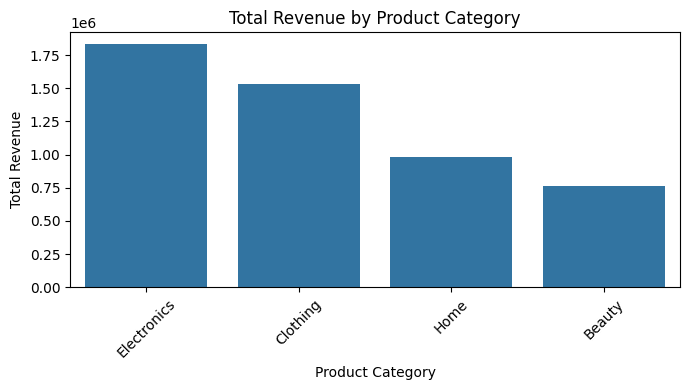

,Total Revenue
product_category,
Electronics,1829899.22
Clothing,1531931.72
Home,982083.92
Beauty,765860.88


In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

category_revenue = df.groupby("product_category")["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=category_revenue.index, y=category_revenue.values)
plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(category_revenue.to_frame("Total Revenue"))


**Observation:** Electronics generated the highest total revenue (1,829,899.22), followed by Clothing (1,531,931.72), Home (982,083.92), and Beauty (765,860.88).


**Insight:** Electronics is the leading revenue-generating category, while Beauty contributes the least. The business could investigate customer preferences, product demand, and marketing strategies to understand these differences and identify opportunities to improve Beauty sales.

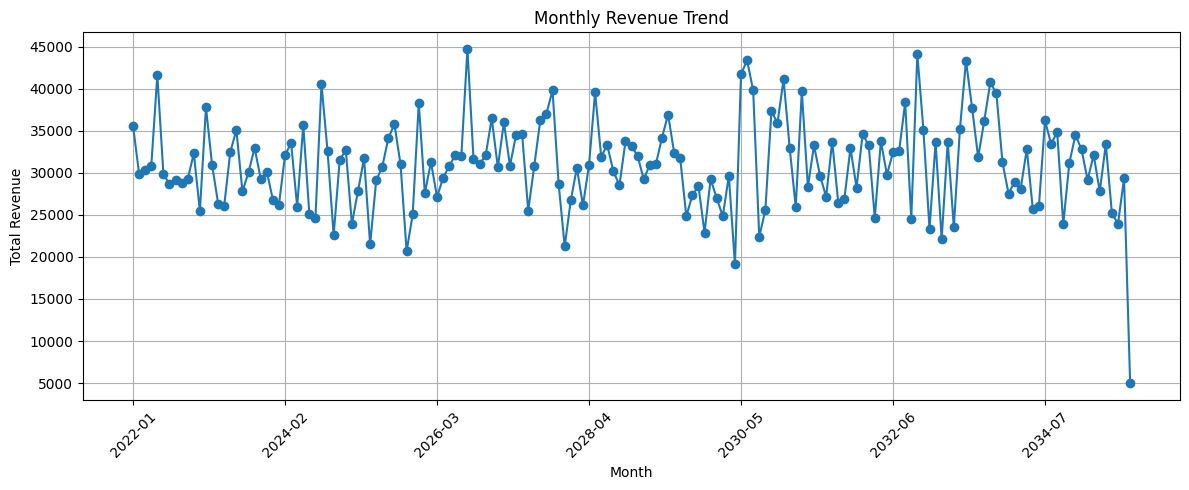

In [37]:

df["month"] = df["order_date"].dt.to_period("M").astype(str)

monthly_revenue = df.groupby("month")["revenue"].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [40]:
print("Earliest order:", df["order_date"].min())
print("Latest order:", df["order_date"].max())

print("\nOrders by year:")
print(df["order_date"].dt.year.value_counts().sort_index())

Earliest order: 2022-01-01 00:00:00
Latest order: 2035-09-09 00:00:00

Orders by year:
order_date
2022    365
2023    365
2024    366
2025    365
2026    365
2027    365
2028    366
2029    365
2030    365
2031    365
2032    366
2033    365
2034    365
2035    252
Name: count, dtype: int64


In [41]:
display(monthly_revenue.sort_values().head(5))
display(monthly_revenue.sort_values(ascending=False).head(5))

,revenue
month,
2035-09,4952.23
2030-04,19101.90
2025-10,20678.85
2027-12,21250.87
2025-04,21502.78


,revenue
month,
2026-08,44728.82
2032-10,44111.58
2030-06,43392.65
2033-06,43362.01
2030-05,41728.40


**Observation:** Monthly revenue fluctuates considerably throughout the dataset. The data covers January 2022 to September 2035. September 2035 has only nine days of recorded data, so its lower revenue may be due to the incomplete month.

**Insight:** Monthly sales show variation rather than a consistent upward or downward trend. Further analysis is needed to identify peak months and determine whether seasonal patterns exist.

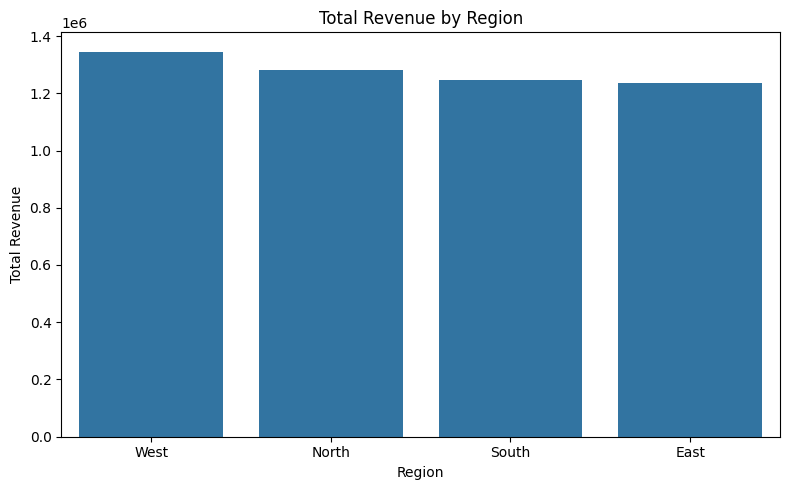

,Total Revenue
region,
West,1345582.16
North,1281508.45
South,1246640.90
East,1236044.23


In [38]:

region_revenue = df.groupby("region")["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=region_revenue.index, y=region_revenue.values)
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

display(region_revenue.to_frame("Total Revenue"))


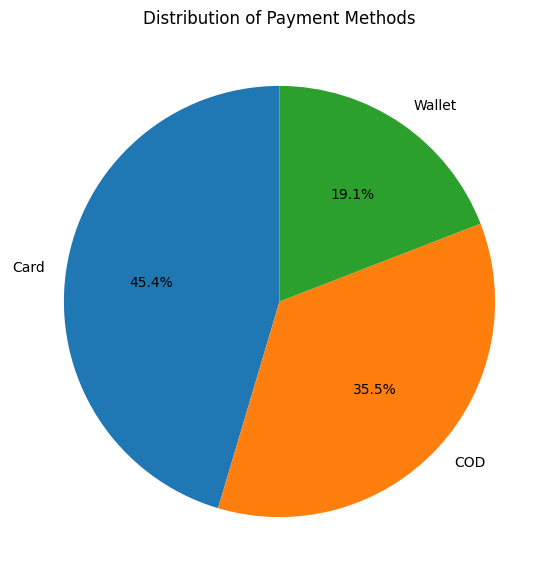

,Number of Orders
payment_method,
Card,2270
COD,1774
Wallet,956


In [39]:

payment_counts = df["payment_method"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(payment_counts, labels=payment_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribution of Payment Methods")
plt.show()

display(payment_counts.to_frame("Number of Orders"))
